In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

SYMBOL = "AAPL"

df = yf.Ticker(SYMBOL).history(
    period="1y",
    interval="1d",
    auto_adjust=True
)

if df.empty:
    raise ValueError("Market data is empty.")

df.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2025-11-25 00:00:00-05:00,274.314343,279.406619,274.294423,276.008453,46914200,0.0,0.0
2025-11-26 00:00:00-05:00,275.998447,278.559532,275.669606,276.586395,33431400,0.0,0.0
2025-11-28 00:00:00-05:00,276.297451,278.031401,275.031841,277.881927,20135600,0.0,0.0
2025-12-01 00:00:00-05:00,277.044832,282.436053,275.181329,282.117157,46587700,0.0,0.0
2025-12-02 00:00:00-05:00,282.017484,286.402202,281.648773,285.196411,53669500,0.0,0.0


In [2]:
OHLCV_COLUMNS = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume"
]

df = df[OHLCV_COLUMNS].copy()

# Sort chronologically
df = df.sort_index()

# Remove duplicate timestamps
df = df.loc[~df.index.duplicated(keep="last")]

# Replace infinite values
df = df.replace([np.inf, -np.inf], np.nan)

# Remove missing observations
df = df.dropna(subset=OHLCV_COLUMNS)

# Validate price and volume
df = df.loc[
    (df[["Open", "High", "Low", "Close"]] > 0).all(axis=1)
    & (df["Volume"] >= 0)
    & (df["High"] >= df[["Open", "Close", "Low"]].max(axis=1))
    & (df["Low"] <= df[["Open", "Close", "High"]].min(axis=1))
].copy()

if len(df) < 2:
    raise ValueError("Insufficient valid market data.")

df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 251 entries, 2025-11-25 00:00:00-05:00 to 2026-11-24 00:00:00-05:00
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    251 non-null    float64
 1   High    251 non-null    float64
 2   Low     251 non-null    float64
 3   Close   251 non-null    float64
 4   Volume  251 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 11.8 KB


In [ ]:
#단순 수익률
df["Simple_Return"] = df["Close"].pct_change(
    fill_method=None
)

df[["Close", "Simple_Return"]].head()

,Close,Simple_Return
Date,,
2025-11-25 00:00:00-05:00,276.008453,NaN
2025-11-26 00:00:00-05:00,276.586395,0.002094
2025-11-28 00:00:00-05:00,277.881927,0.004684
2025-12-01 00:00:00-05:00,282.117157,0.015241
2025-12-02 00:00:00-05:00,285.196411,0.010915


In [ ]:
#로그수익률
df["Log_Return"] = np.log(df["Close"]).diff()

df[["Close", "Simple_Return", "Log_Return"]].head()

,Close,Simple_Return,Log_Return
Date,,,
2025-11-25 00:00:00-05:00,276.008453,NaN,NaN
2025-11-26 00:00:00-05:00,276.586395,0.002094,0.002092
2025-11-28 00:00:00-05:00,277.881927,0.004684,0.004673
2025-12-01 00:00:00-05:00,282.117157,0.015241,0.015126
2025-12-02 00:00:00-05:00,285.196411,0.010915,0.010856


In [7]:
#누적 수익률
df["Cumulative_Return"] = (
    (1 + df["Simple_Return"]).cumprod() - 1
)

df["Cumulative_Log_Return"] = (
    np.exp(df["Log_Return"].cumsum()) - 1
)

df.loc[
    df.index[0],
    ["Cumulative_Return", "Cumulative_Log_Return"]
] = 0.0

df[[
    "Close",
    "Cumulative_Return",
    "Cumulative_Log_Return"
]].tail()

,Close,Cumulative_Return,Cumulative_Log_Return
Date,,,
2026-11-18 00:00:00-05:00,352.450012,0.276954,0.276954
2026-11-19 00:00:00-05:00,349.209991,0.265215,0.265215
2026-11-20 00:00:00-05:00,342.559998,0.241121,0.241121
2026-11-23 00:00:00-05:00,349.079987,0.264744,0.264744
2026-11-24 00:00:00-05:00,354.070007,0.282823,0.282823


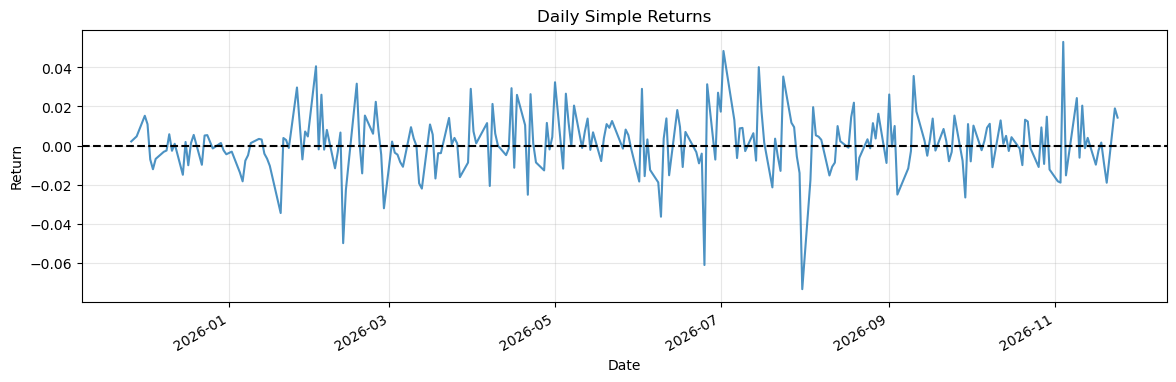

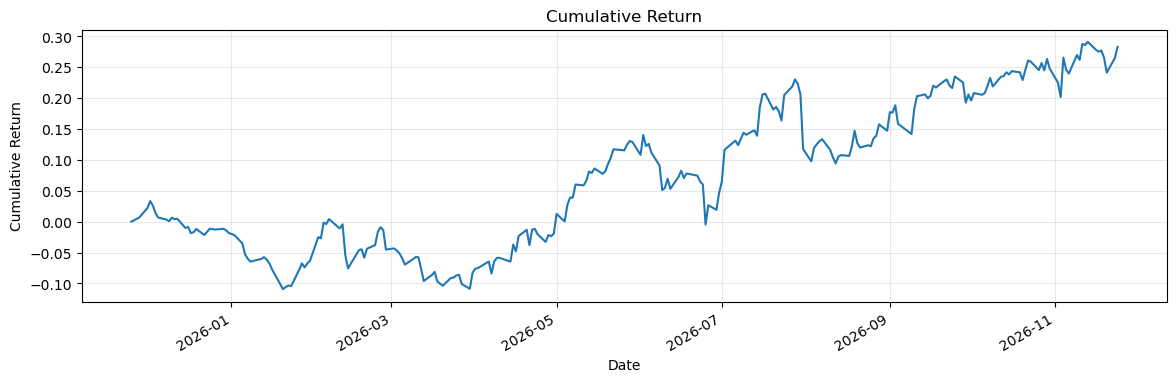

In [8]:
df["Simple_Return"].plot(
    figsize=(14, 4),
    title="Daily Simple Returns",
    alpha=0.8
)

plt.axhline(0, color="black", linestyle="--")
plt.ylabel("Return")
plt.grid(alpha=0.3)
plt.show()

df["Cumulative_Return"].plot(
    figsize=(14, 4),
    title="Cumulative Return"
)

plt.ylabel("Cumulative Return")
plt.grid(alpha=0.3)
plt.show()

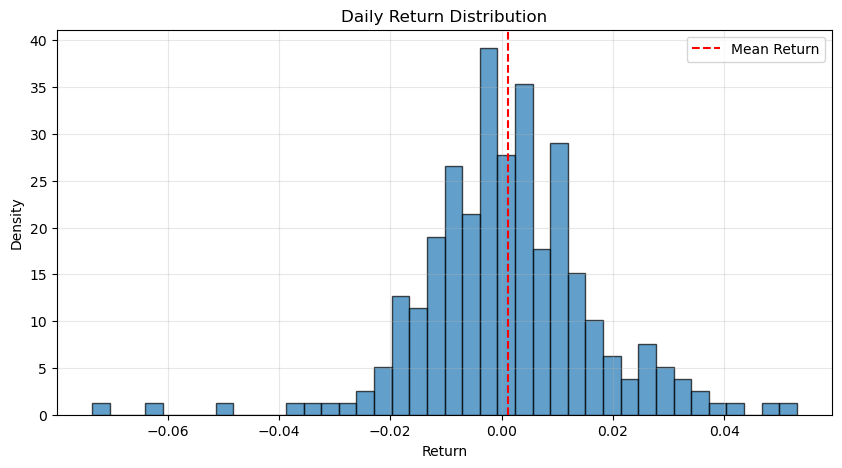

In [9]:
returns = df["Simple_Return"].dropna()

plt.figure(figsize=(10, 5))

plt.hist(
    returns,
    bins=40,
    density=True,
    alpha=0.7,
    edgecolor="black"
)

plt.axvline(
    returns.mean(),
    color="red",
    linestyle="--",
    label="Mean Return"
)

plt.title("Daily Return Distribution")
plt.xlabel("Return")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [10]:
statistics = pd.Series({
    "Mean": returns.mean(),
    "Median": returns.median(),
    "Variance": returns.var(),
    "Standard Deviation": returns.std(),
    "Skewness": returns.skew(),
    "Excess Kurtosis": returns.kurt(),
    "Minimum": returns.min(),
    "Maximum": returns.max()
})

statistics

Mean                  0.001121
Median                0.001102
Variance              0.000248
Standard Deviation    0.015747
Skewness             -0.351301
Excess Kurtosis       3.176218
Minimum              -0.073539
Maximum               0.053058
dtype: float64

In [11]:
from statsmodels.tsa.stattools import adfuller


def adf_test(series):
    result = adfuller(series.dropna(), autolag="AIC")

    return {
        "ADF Statistic": result[0],
        "p-value": result[1],
        "Used Lags": result[2],
        "Observations": result[3]
    }


adf_results = pd.DataFrame({
    "Price": adf_test(df["Close"]),
    "Simple Return": adf_test(df["Simple_Return"]),
    "Log Return": adf_test(df["Log_Return"])
}).T

adf_results

/var/folders/16/rjs4q69s7cb952wmhhws66j00000gn/T/ipykernel_58759/3532830227.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna(), autolag="AIC")
/var/folders/16/rjs4q69s7cb952wmhhws66j00000gn/T/ipykernel_58759/3532830227.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna(), autolag="AIC")
/var/folders/16/rj

,ADF Statistic,p-value,Used Lags,Observations
Price,-0.534931,8.850179e-01,0.0,250.0
Simple Return,-15.943384,7.496607e-29,0.0,249.0
Log Return,-15.897090,8.411384e-29,0.0,249.0
